# Question 3: where do each metro's newcomers come from, and are homes there cheaper?

Source: `gold.mart_migration_origins`, one row per destination metro, origin county and IRS tax year. It holds IRS SOI
county-to-county inflows from U.S. counties outside the metro (moves within the metro are excluded), with the origin
county's and the metro's ZHVI averaged over the move year. `origin_to_metro_zhvi` above 1 means the origin's typical home
costs more than the destination metro's.

Caveats: IRS tax year *t* compares filing addresses in *t*−1 and *t*, so tax year 2023 is mostly moves made in 2022
(`move_year`). Cells under 20 returns are suppressed by the IRS, so small flows are missing. About 0.3% of people come
from counties without a Zillow ZHVI and are left out of the home value comparison. Filers are not all movers: people who
do not file are not counted.

In [1]:
import common as c
from matplotlib.ticker import PercentFormatter

In [2]:
TY = int(c.q("select max(tax_year) from gold.mart_migration_origins").iloc[0, 0])
top = c.q(
    """
    select cbsa_code, origin_name, origin_cbsa_title, people, origin_to_metro_zhvi,
        row_number() over (partition by cbsa_code order by people desc) origin_rank
    from gold.mart_migration_origins where tax_year = $ty
    qualify origin_rank <= 3 order by cbsa_code, origin_rank
    """,
    {"ty": TY},
)
top.insert(0, "metro", top.pop("cbsa_code").map(c.METRO))
print(f"Top 3 origin counties per metro, tax year {TY} (moves in {TY - 1})")
top

Top 3 origin counties per metro, tax year 2023 (moves in 2022)


,metro,origin_name,origin_cbsa_title,people,origin_to_metro_zhvi,origin_rank
0,Atlanta,"Hall County, GA","Gainesville, GA",4074.0,0.976,1
1,Atlanta,"Broward County, FL","Miami-Fort Lauderdale-West Palm Beach, FL",3586.0,1.072,2
2,Atlanta,"Los Angeles County, CA","Los Angeles-Long Beach-Anaheim, CA",3136.0,2.241,3
3,Austin,"Harris County, TX","Houston-Pasadena-The Woodlands, TX",7006.0,0.526,1
4,Austin,"Bexar County, TX","San Antonio-New Braunfels, TX",5210.0,0.505,2
5,Austin,"Bell County, TX","Killeen-Temple, TX",3596.0,0.485,3
6,Charlotte,"Wake County, NC","Raleigh-Cary, NC",2579.0,1.286,1
7,Charlotte,"Catawba County, NC","Hickory-Lenoir-Morganton, NC",2033.0,0.686,2
8,Charlotte,"Guilford County, NC","Greensboro-High Point, NC",1842.0,0.680,3
9,Dallas-Fort Worth,"Harris County, TX","Houston-Pasadena-The Woodlands, TX",9086.0,0.750,1


In [3]:
w = c.q("""
    select cbsa_code, tax_year, move_year, sum(people) people,
        sum(people * origin_to_metro_zhvi) / sum(people) filter (origin_to_metro_zhvi is not null) weighted_ratio,
        sum(people) filter (origin_to_metro_zhvi > 1) / sum(people) filter (origin_to_metro_zhvi is not null) share_pricier
    from gold.mart_migration_origins group by all
""")
w["metro"] = w.cbsa_code.map(c.METRO)
latest = (
    w[w.tax_year == TY]
    .set_index("metro")
    .sort_values("weighted_ratio", ascending=False)
)
latest[["people", "weighted_ratio", "share_pricier"]]

,people,weighted_ratio,share_pricier
metro,,,
Tampa,102203.0,1.177,0.607
Atlanta,101551.0,1.143,0.500
Dallas-Fort Worth,179893.0,1.141,0.448
Orlando,98448.0,1.135,0.550
Charlotte,61486.0,1.090,0.483
Phoenix,134148.0,1.049,0.448
Nashville,41461.0,0.986,0.324
Raleigh,58216.0,0.945,0.306
Denver,76550.0,0.920,0.305


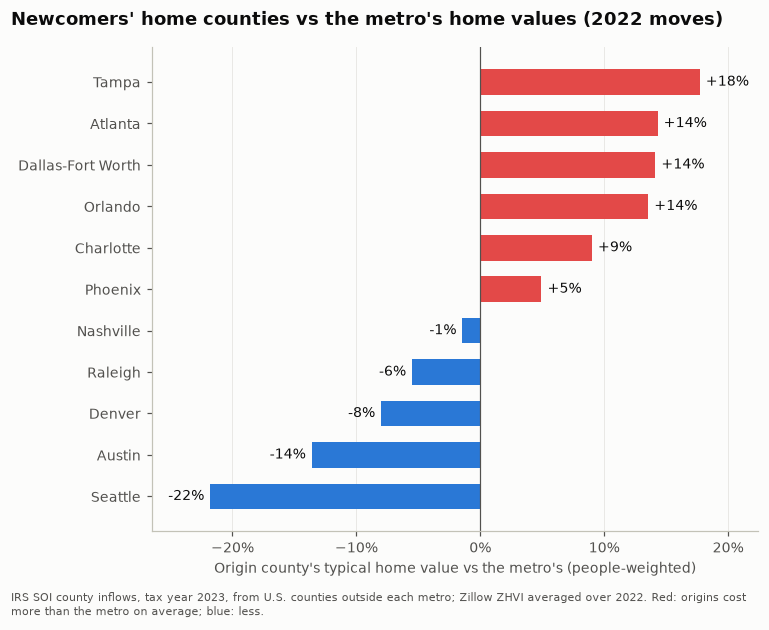

In [4]:
fig, ax = c.ranked_bars(
    latest.weighted_ratio - 1,
    "{:+.0%}",
    PercentFormatter(1, decimals=0),
    diverging=True,
)
ax.set_xlabel("Origin county's typical home value vs the metro's (people-weighted)")
c.save(
    fig,
    "q3_origin_home_values",
    f"Newcomers' home counties vs the metro's home values ({TY - 1} moves)",
    f"IRS SOI county inflows, tax year {TY}, from U.S. counties outside each metro; Zillow ZHVI averaged over {TY - 1}. "
    "Red: origins cost more than the metro on average; blue: less.",
)

How the mix has moved: people-weighted origin-to-metro home value ratio by move year.

In [5]:
w.pivot(index="metro", columns="move_year", values="weighted_ratio").loc[
    latest.index
].round(2)

move_year,2014,2015,2016,2017,2018,2019,2020,2021,2022
metro,,,,,,,,,
Tampa,1.50,1.46,1.40,1.37,1.34,1.35,1.35,1.29,1.18
Atlanta,1.37,1.37,1.35,1.35,1.32,1.34,1.34,1.26,1.14
Dallas-Fort Worth,1.31,1.29,1.26,1.21,1.19,1.23,1.30,1.27,1.14
Orlando,1.29,1.31,1.29,1.25,1.23,1.22,1.23,1.24,1.14
Charlotte,1.36,1.37,1.33,1.31,1.27,1.30,1.30,1.21,1.09
Phoenix,1.26,1.25,1.25,1.28,1.28,1.29,1.24,1.14,1.05
Nashville,1.03,1.05,1.02,0.99,1.01,1.10,1.14,1.13,0.99
Raleigh,1.01,1.04,1.05,1.03,1.04,1.07,1.09,1.05,0.94
Denver,1.03,0.98,0.95,0.95,0.96,0.99,0.98,0.94,0.92


## Answer

In [6]:
hi, lo = latest.iloc[0], latest.iloc[-1]
trend = w.pivot(index="metro", columns="move_year", values="weighted_ratio")
first = trend.columns.min()
print(
    f"In {TY - 1} moves, newcomers to {(latest.weighted_ratio > 1).sum()} of {len(latest)} metros came from counties "
    f"with pricier homes on average, most in {latest.index[0]} ({hi.weighted_ratio - 1:+.0%}, "
    f"{hi.share_pricier:.0%} of people from pricier counties); {latest.index[-1]}'s came from the cheapest "
    f"({lo.weighted_ratio - 1:+.0%}). The ratio fell from {first} to {TY - 1} in "
    f"{(trend[TY - 1] < trend[first]).sum()} of {len(trend)} metros: destination home values rose faster than origins'."
)

In 2022 moves, newcomers to 6 of 11 metros came from counties with pricier homes on average, most in Tampa (+18%, 61% of people from pricier counties); Seattle's came from the cheapest (-22%). The ratio fell from 2014 to 2022 in 11 of 11 metros: destination home values rose faster than origins'.
